# F21: ortho projections are the band coefficients when `los_orbs` is off (implemented)

**Finding** (`notes/theory_audit.md`, F21). With projections that JDFTx made onto orthonormalized orbitals
(`band-projection-params yes ...`, the README's recommended input) and `los_orbs` off, `coef_tju` was a
least-squares fit to the bands. crawfish turns `los_orbs` off by itself whenever `elec-n-bands` is below the number
of orbitals, so every large slab of the research repo's bias-scan studies (2026-11-27) took this path. The fit mixes
the empty bands into the density matrix $D$, so ipCOBI depended on how many empty bands had been computed, and it
jumped between calculations of one geometry. The fix uses the projections themselves, $C=T$.
`legacy_ortho_coefs=True` (cache key `lgoc`) restores the fit.

Data: `N2_bare_min` (z-spin, 3×3×3 k-mesh, 15 bands for 8 orbitals) and `graphene_zspin_full` (z-spin, 12×12×1, 20
bands for 8 orbitals), both with ortho projections and with `los_orbs=False` throughout. Runs with fewer bands are
emulated by keeping the lowest bands, the same states a run with that `elec-n-bands` computes (as
`tests/core/test_ortho_coefs.py::_truncate` does). Both sides use every earlier fix (`load_edata_at`). Figures are
saved to `figures/`. The last cell holds the tests.

## Before and after

Notation as in the README: $T_{\mu,j}(t)=\langle\phi_\mu|\hat O|\psi_j(t)\rangle$ (`proj_tju`), $\epsilon_j(t)$,
$f_j(t)$, $w_t$, and $C_{\mu,j}(t)$ the coefficients (`coef_tju`). At state $t$, $T_t$ is the
$n_{\rm bands}\times n_{\rm proj}$ matrix $(T_t)_{j\mu}=T_{\mu,j}(t)$, i.e. `proj_tju[t]`. With
`band-projection-params yes ...` the $\phi_\mu$ are JDFTx's Löwdin-orthonormalized orbitals,
$\langle\phi_\mu|\hat O|\phi_\nu\rangle=\delta_{\mu\nu}$. crawfish builds the matrices from the bands,

$$
S_{\mu\nu}(t)=\sum_jT_{\mu,j}T^*_{\nu,j},\qquad H_{\mu\nu}(t)=\sum_jT_{\mu,j}\,\epsilon_j\,T^*_{\nu,j},\qquad
D_{\mu\nu}(t)=\sum_jf_j\,C_{\mu,j}C^*_{\nu,j},
$$

and pCOBI is $\sum_{j,t}w_t\,\mathrm{Re}\big[C^*_{\mu,j}D_{\mu\nu}C_{\nu,j}\big]\,\delta\big(E-\epsilon_j(t)\big)$ (pCOHP
the same with $H$, pCOOP with $S$).

**Before.** With `los_orbs` off, the coefficients were the least-squares fit

$$
C_t=T_t\,\big(T_t^\dagger T_t\big)^{+},
$$

where $^+$ is the pseudo-inverse and $T_t^\dagger T_t$ is the complex conjugate of $S(t)$. `alloc_elec_data` turns
`los_orbs` off whenever $n_{\rm bands}<n_{\rm proj}$, so with too few bands this path was taken whatever the user
had set.

**What was wrong.** For orthonormal orbitals the coefficients of $\psi_j$ are its projections,
$C_{\mu,j}=\langle\phi_\mu|\hat O|\psi_j\rangle=T_{\mu,j}$. The fit divides by the band-space overlap instead. Through
$(T_t^\dagger T_t)^+$ every band's coefficients depend on every computed band, the empty ones included, and
directions the bands span poorly (small eigenvalues $\lambda$ of $T_t^\dagger T_t$) are scaled up by $1/\lambda$.
With fewer bands than orbitals, $T_t^\dagger T_t$ has rank $n_{\rm bands}$, so its smallest non-zero eigenvalues
come from whichever empty bands happened to be computed. $D$, and with it ipCOBI, therefore depended on the empty
bands. Evidence from the bias scans (research repo, `crawfish/anl/bias_scans/`):
- dropping the top 5–20 empty bands of NO3 slabs moved ipCOBI by up to 0.43;
- a P–C bond at two neighbouring potentials, with the geometry unchanged, went from ipCOBI 0.625 to 0.936;
- N–O ipCOBI against bond length over 81 bonds gave r = −0.07 with the fit and −0.97 with $C=T$.

**What changed.** For projections that JDFTx made onto orthonormalized orbitals (`bandprojfile_is_ortho`),
`coef_tju` is $C=T$, unless `legacy_ortho_coefs=True`. Unchanged: non-orthogonal projections
(`band-projection-params no no`, where the fit $C=S^{-1}T$ is the right inverse), `los_orbs=True` (the Löwdin step),
the AO-matrix path (already $C=T$) and pDOS ($|T|^2$).

**Now.** $D(t)=\sum_jf_j\,T_{\cdot,j}T^\dagger_{\cdot,j}$ is the occupied density matrix in JDFTx's orbitals. No empty
band enters it, and empty bands carry no ipCOBI weight $f_j\,\mathrm{Re}[T^*_{\mu,j}D_{\mu\nu}T_{\nu,j}]$. ipCOBI is
therefore the same for any `elec-n-bands` that keeps every (partly) occupied band.

**What F21 does not fix.**
- $H(t)$ sums over all computed bands, so ipCOHP still depends on the band count (F14). And
  $\sum_jT_{\cdot,j}T^\dagger_{\cdot,j}=S(t)\ne1$, so shifting the energy zero by $c$ adds $-c\,S_{\mu\nu}$ to
  $H_{\mu\nu}$, and pair ipCOHP depends on `norm_eigs_for_h` (F15). The fit had both problems too.
- The per-band sum rules $\sum_{\mu\nu}\mathrm{Re}[C^*_{\mu,j}S_{\mu\nu}C_{\nu,j}]=1$ and
  $\sum_{\mu\nu}\mathrm{Re}[C^*_{\mu,j}H_{\mu\nu}C_{\nu,j}]=\epsilon_j$ hold when $G_{ji}=\sum_\mu C^*_{\mu,j}T_{\mu,i}$ is
  the identity. For the fit $G$ is a projector of rank $\min(n_{\rm bands},n_{\rm proj})$: the identity with at most
  as many bands as orbitals. For $C=T$ it is $\Pi_{ji}=\sum_\mu T^*_{\mu,j}T_{\mu,i}$, whose diagonal is one minus
  band $j$'s charge spilling. On this path the occupation-weighted sums come out 1–4 % short.

| issue | example below |
|---|---|
| with all bands, the fit over-counts $\mathrm{Tr}\,D$ and ipCOBI | N2 table, 15 bands |
| ipCOBI depends on the empty bands (fit) | ipCOBI against the number of bands kept, N2 and graphene |
| | N2 pCOBI spectra with 15 and 7 bands, and their difference; graphene pCOBI with 20 and 7 bands |
| limits: ipCOHP's band count and energy zero, the sum rules | ipCOHP against the bands kept; table of the limits |

In [1]:
import sys
import tempfile
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))  # fixcompare.py lives next to this notebook (run with this directory as cwd)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fixcompare import *
from crawfish.funcs import get_ipcobi, get_ipcohp, get_pcobi
from crawfish.funcs.general import SIGMA_DEFAULT

LEGACY_C, FIXED_C = "#eb6834", "#2a78d6"  # categorical slots 2 and 1 of the default palette
assert fix_available("F21")
SYSTEMS = {"N2": N2_CALC_DIR, "graphene": Path(EXAMPLE_CALC_DIRS_DIR) / "graphene_zspin_full"}
CUT_DIR = tempfile.TemporaryDirectory(prefix="F21_")  # matrices of band-cut data, never the fixtures' cache


def quiet(f, *args, **kwargs):
    """Run f with warnings silenced (the too-few-bands and Löwdin warnings are not the subject here)."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return f(*args, **kwargs)


def truncated(edata, nb):
    """Keep the lowest nb bands, the states a run with elec-n-bands nb computes (tests/core/test_ortho_coefs.py).
    The matrices are rebuilt in a scratch cache dir."""
    edata._proj_tju = np.ascontiguousarray(edata.proj_tju[:, :nb])
    edata._e_tj = np.ascontiguousarray(edata.e_tj[:, :nb])
    edata._occ_tj = np.ascontiguousarray(edata.occ_tj[:, :nb])
    edata._nbands = nb
    edata._coef_tju = edata._h_t_uv = edata._s_t_uv = edata._d_t_uv = None
    edata.cache_sub_dir = Path(tempfile.mkdtemp(dir=CUT_DIR.name))
    return edata


def load(name, fixed, nb=None, **settings):
    """N2 or graphene with los_orbs off, F21 fixed (C = T) or legacy (fit); nb keeps the lowest nb bands."""
    edata = quiet(load_edata_at, "F21", fixed, calc_dir=SYSTEMS[name], los_orbs=False, **settings)
    return edata if nb is None else truncated(edata, nb)


def bond(func, edata, **kwargs):
    """Integrated value of atom 1 - atom 2 (nearest image), uncached."""
    return last_value(quiet(func, edata, idcs1=0, idcs2=1, use_cache=False, **kwargs))


def n_occupied(edata):
    """Number of bands with any occupation: the smallest cut that keeps every occupied band."""
    return int(np.max(np.nonzero(np.asarray(edata.occ_tj) > 1e-8)[1])) + 1


def sum_rules(edata):
    """Occupation-weighted sums over all orbital pairs (on-site included), relative to their exact values."""
    w, f = np.asarray(edata.wk_t, np.float64), np.asarray(edata.occ_tj, np.float64)
    C = np.asarray(edata.coef_tju, np.complex128)
    e = np.asarray(edata.e_tj, np.float64) - (edata.mu if edata.norm_eigs_for_h else 0.0)  # the energies in H
    wf = w[:, None] * f
    pair_sum = lambda M: float(np.einsum("tj,tju,tuv,tjv->", wf, C.conj(), np.asarray(M, np.complex128), C).real)
    trace_d = float(np.einsum("t,tuu->", w, np.asarray(edata.d_t_uv, np.complex128)).real)
    return {"band energy / Σ w f ε": pair_sum(edata.h_t_uv) / float(np.sum(wf * e)),
            "electron count / N_e": pair_sum(edata.s_t_uv) / wf.sum(), "Tr D / N_e": trace_d / wf.sum()}


spec_kwargs = dict(use_cache=False, use_cached_spectrum=False, save_spectrum=False)
NB_CUT = {name: n_occupied(load(name, True)) + 2 for name in SYSTEMS}  # two empty bands, fewer than the 8 orbitals
NB_CUT

{'N2': 7, 'graphene': 7}

## N2 with all 15 bands

Here `los_orbs=False` is set by hand, so the fit is not forced by too few bands. Both coefficient sets describe the
same 15 bands. The fit's $D$ over-counts the electrons ($\mathrm{Tr}\,D/N_e>1$, limits table below), and the fix
lowers ipCOBI by 9 % and ipCOHP by 2 %. Default settings (`los_orbs` on) and non-orthogonal projections do not
change.

In [2]:
n2 = {"legacy": load("N2", False), "fixed": load("N2", True)}
PAIRS = [(None, None), ("s", "s"), ("s", "px"), ("px", "px"), ("py", "py")]
n2_table = pd.DataFrame({(q, name): [bond(func, ed, orbs1=a, orbs2=b) for a, b in PAIRS]
                         for q, func in [("ipCOBI", get_ipcobi), ("ipCOHP (Ha)", get_ipcohp)] for name, ed in n2.items()},
                        index=[f"{a or 'all'}–{b or 'all'}" for a, b in PAIRS])
for q in ["ipCOBI", "ipCOHP (Ha)"]:
    n2_table[(q, "fixed − legacy")] = n2_table[(q, "fixed")] - n2_table[(q, "legacy")]
display(n2_table.round(4))

unchanged = {}
for label, kwargs in [("N2, default settings (los_orbs on)", dict(calc_dir=N2_CALC_DIR)),
                      ("N2 no-spin, non-ortho projections, los_orbs off",
                       dict(calc_dir=Path(EXAMPLE_CALC_DIRS_DIR) / "N2_nospin_nonortho15", los_orbs=False))]:
    eds = {name: quiet(load_edata_at, "F21", name == "fixed", **kwargs) for name in ("legacy", "fixed")}
    unchanged[label] = {"ipCOBI, legacy": bond(get_ipcobi, eds["legacy"]), "ipCOBI, fixed": bond(get_ipcobi, eds["fixed"]),
                        "max |C fixed − C legacy|": float(np.abs(eds["fixed"].coef_tju - eds["legacy"].coef_tju).max())}
unchanged_table = pd.DataFrame(unchanged).T
unchanged_table

ipCOBI         ipCOHP (Ha)                 ipCOBI    ipCOHP (Ha)
         legacy   fixed      legacy   fixed fixed − legacy fixed − legacy
all–all  1.5645  1.4219     -0.7859 -0.7690        -0.1426         0.0169
s–s      0.0603  0.0859     -0.0865 -0.1031         0.0255        -0.0167
s–px     0.1154  0.1199     -0.1190 -0.1213         0.0045        -0.0023
px–px    0.2381  0.1390     -0.1033 -0.0789        -0.0992         0.0244
py–py    0.5177  0.4787     -0.1791 -0.1722        -0.0390         0.0069

,"ipCOBI, legacy","ipCOBI, fixed",max |C fixed − C legacy|
"N2, default settings (los_orbs on)",1.493494,1.493494,0.0
"N2 no-spin, non-ortho projections, los_orbs off",1.126464,1.126464,0.0


## Dropping empty bands

Each calculation cut to its lowest $n$ bands, from the (partly) occupied bands (5 for both) up to all computed
bands. Left of the grey band boundary there are fewer bands than the 8 orbitals: there crawfish forces `los_orbs`
off, the bias-scan situation. With $C=T$ (blue), ipCOBI is the same at every cut. The fit (orange) moves. For N2 it
moves by 1–1.5 % (and by a third at exactly 8 bands, where $T_t^\dagger T_t$ is square and ill-conditioned). For
graphene with 6 to 13 bands it is 20 to $5\times10^5$ times too large (log axis), as the poorly spanned directions
are scaled up. ipCOHP (right) still moves with the band count with $C=T$, by 4 % for N2 and by a factor of 2 for
graphene (F14, limits below).

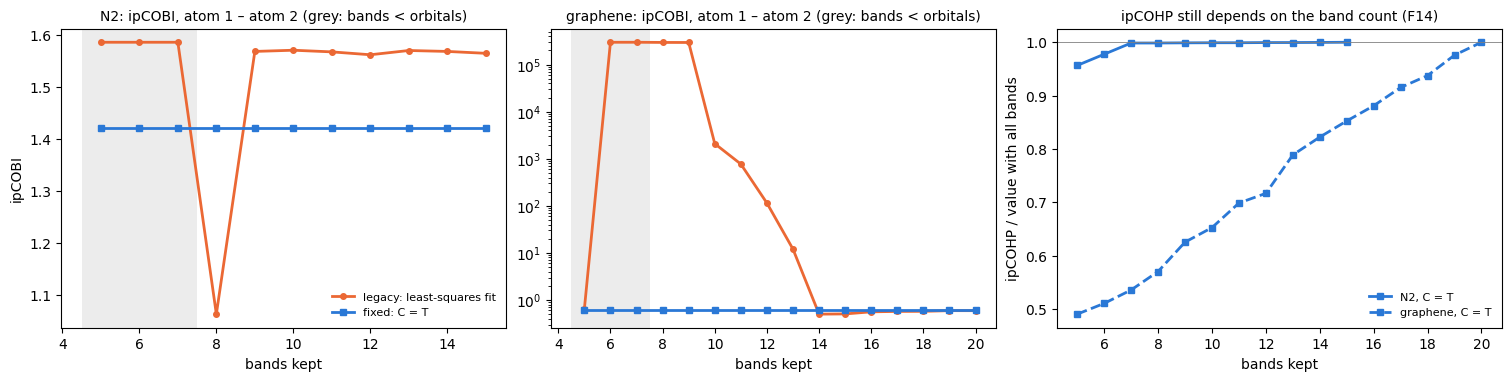

ipCOBI              ipCOHP (Ha)         
coefficients          fixed       legacy       fixed   legacy
system   bands kept                                          
N2       5           1.4219       1.5858     -0.7356  -0.7709
         6           1.4219       1.5858     -0.7518  -0.7878
         7           1.4219       1.5858     -0.7679  -0.8047
         8           1.4219       1.0636     -0.7679  -0.4156
         9           1.4219       1.5682     -0.7682  -0.7874
         10          1.4219       1.5705     -0.7683  -0.7867
         11          1.4219       1.5673     -0.7683  -0.7861
         12          1.4219       1.5618     -0.7686  -0.7825
         13          1.4219       1.5699     -0.7686  -0.7865
         14          1.4219       1.5682     -0.7688  -0.7865
         15          1.4219       1.5645     -0.7690  -0.7859
graphene 5           0.6046       0.6456     -0.2241  -0.2295
         6           0.6046  298358.2500     -0.2333  60.7595
         7           0.6046  298609.4688     -0.2448  68.4204
         8           0.6046  296139.1562     -0.2606  64.1442
         9           0.6046  295444.7812     -0.2858  80.5262
         10          0.6046    2093.4080     -0.2982   8.1342
         11          0.6046     771.2401     -0.3193   4.8155
         12          0.6046     114.6457     -0.3276   1.8072
         13          0.6046      12.0236     -0.3606   0.4605
         14          0.6046       0.5009     -0.3759  -0.3358
         15          0.6046       0.5059     -0.3897  -0.3501
         16          0.6046       0.5605     -0.4027  -0.3856
         17          0.6046       0.5720     -0.4184  -0.4047
         18          0.6046       0.5743     -0.4286  -0.4152
         19          0.6046       0.5938     -0.4461  -0.4404
         20          0.6046       0.5933     -0.4571  -0.4509

In [3]:
full = {(name, fixed): load(name, fixed) for name in SYSTEMS for fixed in (False, True)}
rows = {}
for (name, fixed), ed_full in full.items():
    for nb in range(n_occupied(ed_full), ed_full.nbands + 1):
        ed = ed_full if nb == ed_full.nbands else load(name, fixed, nb)
        rows[(name, "fixed" if fixed else "legacy", nb)] = {"ipCOBI": bond(get_ipcobi, ed), "ipCOHP (Ha)": bond(get_ipcohp, ed)}
series = pd.DataFrame(rows).T.sort_index()
series.index.names = ["system", "coefficients", "bands kept"]
NPROJ = {name: full[(name, True)].nproj for name in SYSTEMS}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.7), layout="constrained")
for ax, name in zip(axes[:2], SYSTEMS):
    for coefs, c, marker, label in [("legacy", LEGACY_C, "o", "legacy: least-squares fit"), ("fixed", FIXED_C, "s", "fixed: C = T")]:
        s = series.loc[(name, coefs), "ipCOBI"]
        ax.plot(s.index, s.values, color=c, marker=marker, markersize=4, linewidth=2, label=label)
    ax.axvspan(series.loc[(name, "fixed")].index.min() - 0.5, NPROJ[name] - 0.5, color="gray", alpha=0.15, linewidth=0)
    ax.set_title(f"{name}: ipCOBI, atom 1 – atom 2 (grey: bands < orbitals)", fontsize=10)
    ax.set_xlabel("bands kept")
axes[0].set_ylabel("ipCOBI")
axes[0].legend(frameon=False, fontsize=8)
axes[1].set_yscale("log")
for name, ls in [("N2", "-"), ("graphene", "--")]:
    s = series.loc[(name, "fixed"), "ipCOHP (Ha)"]
    axes[2].plot(s.index, s / s.iloc[-1], color=FIXED_C, linestyle=ls, marker="s", markersize=4, linewidth=2,
                 label=f"{name}, C = T")
axes[2].axhline(1, color="gray", linewidth=0.6)
axes[2].set_title("ipCOHP still depends on the band count (F14)", fontsize=10)
axes[2].set_xlabel("bands kept")
axes[2].set_ylabel("ipCOHP / value with all bands")
axes[2].legend(frameon=False, fontsize=8)
savefig(fig, "F21_band_drop")
plt.show()

series.unstack("coefficients").round(4)

### pCOBI spectra

N2's N1–N2 pCOBI with all 15 bands and with 7 (the occupied bands plus the degenerate π* pair, one band fewer than
orbitals). The window ends 2 eV above $\mu_F$, past the π* LUMO; the next band lies 2.5 eV above $\mu_F$. With
$C=T$ the two spectra coincide. With the fit the whole spectrum changes when the empty bands go, because every band's
coefficients change. Graphene (right) with 20 and 7 bands: with $C=T$ the spectra coincide too (the dropped bands
start 7.6 eV above $\mu_F$, outside the window). The fit with 7 bands is off this scale (title).

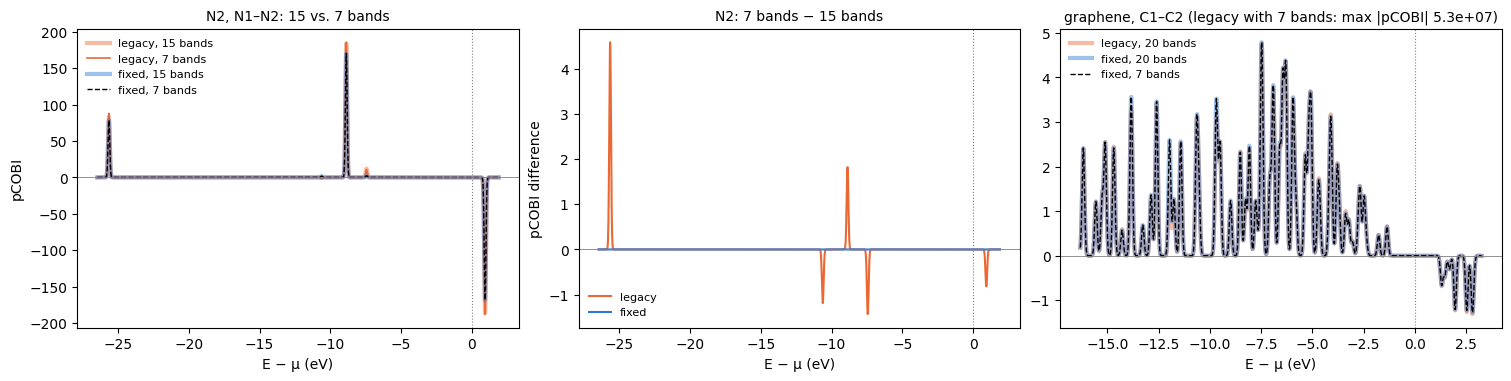

In [4]:
def pcobi(edata, erange):
    return np.ravel(np.asarray(quiet(get_pcobi, edata, idcs1=0, idcs2=1, erange=erange, sig=SIGMA_DEFAULT, **spec_kwargs)[1]))


ERANGES = {"N2": np.arange(n2["fixed"].e_tj.min() - 0.03, n2["fixed"].mu + 0.07, 0.0005, dtype=np.float32),
           "graphene": np.arange(full[("graphene", True)].mu - 0.6, full[("graphene", True)].mu + 0.12, 0.0005,
                                 dtype=np.float32)}
specs = {}
for name in SYSTEMS:
    for fixed in (False, True):
        coefs = "fixed" if fixed else "legacy"
        specs[(name, coefs, "all bands")] = pcobi(full[(name, fixed)], ERANGES[name])
        specs[(name, coefs, "cut")] = pcobi(load(name, fixed, NB_CUT[name]), ERANGES[name])

STYLES = {("legacy", "all bands"): dict(color=LEGACY_C, linewidth=3, alpha=0.45),
          ("legacy", "cut"): dict(color=LEGACY_C, linewidth=1.2),
          ("fixed", "all bands"): dict(color=FIXED_C, linewidth=3, alpha=0.45),
          ("fixed", "cut"): dict(color="black", linewidth=1, linestyle="--")}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.7), layout="constrained")
x = {name: to_ev_rel_mu(full[(name, True)], ERANGES[name]) for name in SYSTEMS}
nb_all = {name: full[(name, True)].nbands for name in SYSTEMS}
for (coefs, which), style in STYLES.items():
    label = f"{coefs}, {nb_all['N2'] if which == 'all bands' else NB_CUT['N2']} bands"
    axes[0].plot(x["N2"], specs[("N2", coefs, which)], label=label, **style)
for coefs, c in [("legacy", LEGACY_C), ("fixed", FIXED_C)]:
    axes[1].plot(x["N2"], specs[("N2", coefs, "cut")] - specs[("N2", coefs, "all bands")], color=c, linewidth=1.5,
                 label=coefs)
for (coefs, which), style in STYLES.items():
    if (coefs, which) != ("legacy", "cut"):
        label = f"{coefs}, {nb_all['graphene'] if which == 'all bands' else NB_CUT['graphene']} bands"
        axes[2].plot(x["graphene"], specs[("graphene", coefs, which)], label=label, **style)
legacy_cut_max = np.max(np.abs(specs[("graphene", "legacy", "cut")]))
axes[0].set_title(f"N2, N1–N2: {nb_all['N2']} vs. {NB_CUT['N2']} bands", fontsize=10)
axes[1].set_title(f"N2: {NB_CUT['N2']} bands − {nb_all['N2']} bands", fontsize=10)
axes[2].set_title(f"graphene, C1–C2 (legacy with {NB_CUT['graphene']} bands: max |pCOBI| {legacy_cut_max:.1e})", fontsize=10)
axes[0].set_ylabel("pCOBI")
axes[1].set_ylabel("pCOBI difference")
for ax in axes:
    ax.axvline(0, color="gray", linewidth=0.8, linestyle=":")
    ax.axhline(0, color="gray", linewidth=0.6)
    ax.set_xlabel("E − μ (eV)")
    ax.legend(frameon=False, fontsize=8)
savefig(fig, "F21_pcobi_spectra")
plt.show()

## What F21 does not fix

The right panel of the band-drop figure shows ipCOHP's band-count dependence (F14). The table adds the energy zero
(F15) and the sum rules, for all bands and for the cut to 7 bands:
- **Energy zero.** ipCOHP with energies measured from $\mu_F$ (`norm_eigs_for_h=True`, the default) and absolute.
  N2 moves by 6 % with either coefficient set ($\mu_F=-0.096$ Ha). Graphene barely moves, only because its
  $\mu_F=-0.024$ Ha is close to zero.
- **Sum rules.** With $C=T$ the band-energy sums come out 3–4 % short, the electron counts 1–4 %, and
  $\mathrm{Tr}\,D/N_e$ 1–2 % (charge spilling). The fit gives 1 (to 0.2 %) with fewer bands than orbitals, and less
  with more bands (graphene, 20 bands: 0.970), but its $\mathrm{Tr}\,D$ over-counts: by 2 % for N2, and by a factor
  of 240 for graphene cut to 7 bands.

In [5]:
rows = {}
for name in SYSTEMS:
    for label, nb in [("all bands", None), (f"{NB_CUT[name]} bands", NB_CUT[name])]:
        for fixed in (False, True):
            ed = load(name, fixed, nb)
            rows[(name, label, "fixed" if fixed else "legacy")] = {
                "ipCOHP, E − μ": bond(get_ipcohp, ed),
                "ipCOHP, absolute E": bond(get_ipcohp, load(name, fixed, nb, norm_eigs_for_h=False)),
                **sum_rules(ed)}
limits = pd.DataFrame(rows).T
limits.index.names = ["system", "bands", "coefficients"]
limits.round(4)

ipCOHP, E − μ  ipCOHP, absolute E  \
system   bands     coefficients                                      
N2       all bands legacy              -0.7859             -0.8329   
                   fixed               -0.7690             -0.8137   
         7 bands   legacy              -0.8047             -0.8535   
                   fixed               -0.7679             -0.8134   
graphene all bands legacy              -0.4509             -0.4525   
                   fixed               -0.4571             -0.4589   
         7 bands   legacy              68.4204             70.7719   
                   fixed               -0.2448             -0.2559   

                                 band energy / Σ w f ε  electron count / N_e  \
system   bands     coefficients                                                
N2       all bands legacy                       0.9966                0.9981   
                   fixed                        0.9602                0.9613   
         7 bands   legacy                       1.0000                1.0000   
                   fixed                        0.9606                0.9596   
graphene all bands legacy                       0.9699                0.9917   
                   fixed                        0.9649                0.9870   
         7 bands   legacy                       0.9982                0.9991   
                   fixed                        0.9720                0.9826   

                                 Tr D / N_e  
system   bands     coefficients              
N2       all bands legacy            1.0206  
                   fixed             0.9794  
         7 bands   legacy            1.0215  
                   fixed             0.9794  
graphene all bands legacy            1.0072  
                   fixed             0.9892  
         7 bands   legacy          240.9890  
                   fixed             0.9892

## Tests

In [6]:
# C = T on the fixed path, the least-squares fit on the legacy path
assert np.array_equal(n2["fixed"].coef_tju, n2["fixed"].proj_tju)
assert not np.allclose(n2["legacy"].coef_tju, n2["legacy"].proj_tju, atol=1e-4)
assert "lgoc_False" in n2["fixed"].cache_sub_dir.name and "lgoc_True" in n2["legacy"].cache_sub_dir.name
# N2, 15 bands (numbers in notes/theory_audit.md, F21): ipCOBI 1.5645 -> 1.4219, ipCOHP -0.786 -> -0.769
assert np.allclose(n2_table.loc["all–all", [("ipCOBI", "legacy"), ("ipCOBI", "fixed")]], [1.5645, 1.4219], atol=2e-4)
assert np.allclose(n2_table.loc["all–all", [("ipCOHP (Ha)", "legacy"), ("ipCOHP (Ha)", "fixed")]], [-0.7859, -0.7690],
                   atol=2e-4)
# los_orbs on and non-ortho projections are untouched
assert (unchanged_table["max |C fixed − C legacy|"] == 0).all()
assert np.allclose(unchanged_table["ipCOBI, legacy"], unchanged_table["ipCOBI, fixed"], atol=0)
# Dropping empty bands: C = T leaves ipCOBI unchanged at every cut, the fit moves
for name in SYSTEMS:
    fixed_cobi, legacy_cobi = series.loc[(name, "fixed"), "ipCOBI"], series.loc[(name, "legacy"), "ipCOBI"]
    assert np.ptp(fixed_cobi.to_numpy()) < 1e-5, (name, np.ptp(fixed_cobi.to_numpy()))
    below = legacy_cobi.index < NPROJ[name]  # fewer bands than orbitals: los_orbs is forced off there
    assert np.max(np.abs(legacy_cobi[below] - legacy_cobi.iloc[-1])) > 1e-2, name
assert series.loc[("graphene", "legacy", 7), "ipCOBI"] > 1e5
assert abs(series.loc[("N2", "legacy", 8), "ipCOBI"] / series.loc[("N2", "legacy", 15), "ipCOBI"] - 1) > 0.25
# Spectra: the C = T spectrum is unchanged by the cut (the dropped bands lie above both windows), the fit's is not
n2_scale = np.max(np.abs(specs[("N2", "fixed", "all bands")]))
assert np.max(np.abs(specs[("N2", "fixed", "cut")] - specs[("N2", "fixed", "all bands")])) < 1e-5 * n2_scale
assert np.max(np.abs(specs[("N2", "legacy", "cut")] - specs[("N2", "legacy", "all bands")])) > 1e-2 * n2_scale
gr_scale = np.max(np.abs(specs[("graphene", "fixed", "all bands")]))
assert np.max(np.abs(specs[("graphene", "fixed", "cut")] - specs[("graphene", "fixed", "all bands")])) < 1e-5 * gr_scale
assert legacy_cut_max > 1e3 * gr_scale
# Limits: ipCOHP still moves with the band count (F14) and the energy zero (F15); sum rules 1-4 % short with C = T
for name, min_change in [("N2", 0.03), ("graphene", 0.4)]:
    s = series.loc[(name, "fixed"), "ipCOHP (Ha)"]
    assert abs(s.iloc[0] / s.iloc[-1] - 1) > min_change, name
n2_zero = limits.loc[("N2", "all bands", "fixed")]
assert abs(n2_zero["ipCOHP, absolute E"] / n2_zero["ipCOHP, E − μ"] - 1) > 0.04
fixed_rows = limits.xs("fixed", level="coefficients")
assert fixed_rows[["band energy / Σ w f ε", "electron count / N_e"]].stack().between(0.955, 0.99).all()
assert fixed_rows["Tr D / N_e"].between(0.97, 1.0).all()
legacy_cut = limits.loc[[(name, f"{NB_CUT[name]} bands", "legacy") for name in SYSTEMS]]
assert np.allclose(legacy_cut[["band energy / Σ w f ε", "electron count / N_e"]], 1, atol=3e-3)
assert (limits.xs("legacy", level="coefficients")["Tr D / N_e"] > 1.0).all()
print("All F21 checks passed.")

All F21 checks passed.
